# <center>Hybrid Search RAG | Chapter 4 </center>
## TF-IDF — Term Frequency × Inverse Document Frequency


# Learning Flow

```text
WHY TF-IDF EXISTS
       ↓
TERM FREQUENCY
       ↓
DOCUMENT FREQUENCY
       ↓
INVERSE DOCUMENT FREQUENCY
       ↓
TF × IDF
       ↓
DOCUMENT VECTORS
       ↓
QUERY VECTOR
       ↓
COSINE SIMILARITY
       ↓
RANKING
       ↓
LIMITATIONS
       ↓
WHY BM25 IMPROVES IT
```

---

# What You Will Learn

By the end of this notebook, you should be able to explain and implement:

- Why simple keyword counting is not enough
- Term Frequency (TF)
- Raw TF
- Normalized TF
- Log-scaled TF
- Document Frequency (DF)
- Inverse Document Frequency (IDF)
- Why rare words matter more
- Why common words matter less
- TF-IDF formula
- Manual TF-IDF calculation
- TF-IDF vectors
- Query TF-IDF
- Cosine similarity
- Search ranking
- Vocabulary matrix
- Sparse representation
- TF-IDF visualization
- TF-IDF from scratch
- Scikit-learn TF-IDF
- TF-IDF failure cases
- Long-document problem
- Repeated-term saturation problem
- Vocabulary mismatch
- Why BM25 improves on TF-IDF

---

# Core Mental Model

```text
TF asks:

"How important is this word INSIDE this document?"

IDF asks:

"How rare is this word ACROSS all documents?"

TF-IDF asks:

"Is this word important here AND uncommon globally?"
```

# 0. How to Study This Notebook

For each section:

```text
Read theory
   ↓
See visual
   ↓
Predict result
   ↓
Run code
   ↓
Inspect printed values
   ↓
Answer checkpoint
   ↓
Check answer
```

Do not just memorize formulas.

Your goal is to understand **why each number exists** before using libraries.

# 1. Setup

We will use simple examples only:

- cats
- dogs
- apples
- fruits
- small school-style documents

Libraries:

- `numpy`
- `pandas`
- `matplotlib`
- `scikit-learn`

In [4]:
import math
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

print("Setup complete.")

Setup complete.


# 2. Why Is Simple Word Counting Not Enough?

Suppose we have:

```text
D1: cat cat milk
D2: cat dog food
D3: dog dog food
```

User searches:

```text
cat
```

Simple counting says:

```text
D1 → cat appears 2 times
D2 → cat appears 1 time
D3 → cat appears 0 times
```

So D1 should rank above D2. That makes sense.

But counting alone ignores another question:

> Is the word rare and informative across the whole collection?

This gives us two signals:

```text
LOCAL importance  → TF
GLOBAL rarity     → IDF
```

In [6]:
documents = {
    "D1": "cat cat milk",
    "D2": "cat dog food",
    "D3": "dog dog food",
    "D4": "apple banana fruit",
    "D5": "apple fruit salad"
}

print("DOCUMENTS")
print("=" * 50)

for doc_id, text in documents.items():
    print(f"{doc_id}: {text}")

DOCUMENTS
D1: cat cat milk
D2: cat dog food
D3: dog dog food
D4: apple banana fruit
D5: apple fruit salad


# 3. Visual Intuition — TF and IDF Answer Different Questions

```text
        TERM
       /    \
      /      \
     ▼        ▼
    TF        IDF
     │         │
     │         │
 inside      across
 one doc     all docs
     \         /
      \       /
       ▼     ▼
      TF-IDF
```

Final importance:

```text
TF-IDF = TF × IDF
```

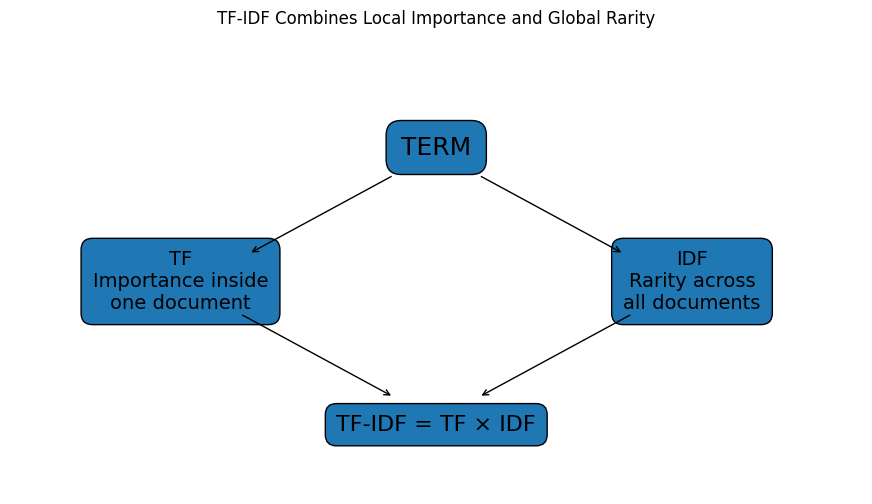

In [3]:
fig, ax = plt.subplots(figsize=(11, 6))
ax.axis("off")

ax.text(0.5, 0.75, "TERM", ha="center", va="center", fontsize=18,
        bbox=dict(boxstyle="round,pad=0.6"))
ax.text(0.2, 0.46, "TF\nImportance inside\none document", ha="center", va="center", fontsize=14,
        bbox=dict(boxstyle="round,pad=0.6"))
ax.text(0.8, 0.46, "IDF\nRarity across\nall documents", ha="center", va="center", fontsize=14,
        bbox=dict(boxstyle="round,pad=0.6"))
ax.text(0.5, 0.15, "TF-IDF = TF × IDF", ha="center", va="center", fontsize=16,
        bbox=dict(boxstyle="round,pad=0.5"))

ax.annotate("", xy=(0.28, 0.52), xytext=(0.45, 0.69), arrowprops=dict(arrowstyle="->"))
ax.annotate("", xy=(0.72, 0.52), xytext=(0.55, 0.69), arrowprops=dict(arrowstyle="->"))
ax.annotate("", xy=(0.45, 0.21), xytext=(0.27, 0.39), arrowprops=dict(arrowstyle="->"))
ax.annotate("", xy=(0.55, 0.21), xytext=(0.73, 0.39), arrowprops=dict(arrowstyle="->"))

plt.title("TF-IDF Combines Local Importance and Global Rarity")
plt.show()

# 4. First Step — Tokenization

Before counting terms, we convert text into tokens.

```text
"Cat drinks milk."
        ↓
["cat", "drinks", "milk"]
```

In [7]:
def tokenize(text):
    return re.findall(r"[a-z0-9]+", text.lower())

example = "Cat drinks milk."

print("Original:")
print(example)
print("\nTokens:")
print(tokenize(example))

Original:
Cat drinks milk.

Tokens:
['cat', 'drinks', 'milk']


# 5. Term Frequency (TF)

TF asks:

> How often does a term appear inside this document?

Simplest formula:

\[
TF(t,d)=count(t,d)
\]

Example:

```text
D1: cat cat milk

TF(cat, D1)  = 2
TF(milk, D1) = 1
TF(dog, D1)  = 0
```

In [8]:
def raw_tf(term, text):
    tokens = tokenize(text)
    counts = Counter(tokens)

    print("TEXT:")
    print(text)
    print("\nTOKENS:")
    print(tokens)
    print("\nCOUNTS:")
    print(counts)

    value = counts[term.lower()]
    print(f"\nTF('{term}') = {value}")

    return value

raw_tf("cat", documents["D1"])

TEXT:
cat cat milk

TOKENS:
['cat', 'cat', 'milk']

COUNTS:
Counter({'cat': 2, 'milk': 1})

TF('cat') = 2


2

# 6. Visualize TF

For:

```text
D1: cat cat milk
```

we have:

```text
cat  → 2
milk → 1
```

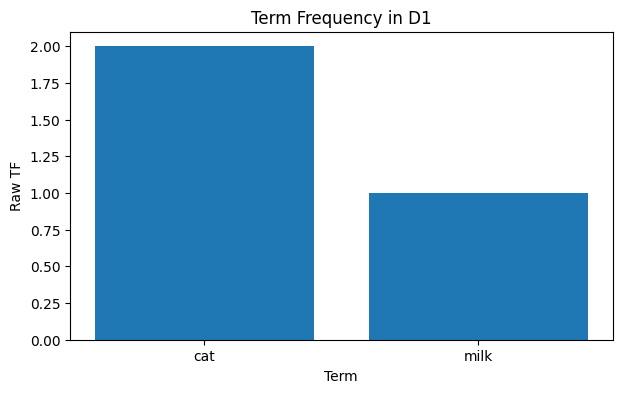

In [9]:
counts = Counter(tokenize(documents["D1"]))

plt.figure(figsize=(7, 4))
plt.bar(list(counts.keys()), list(counts.values()))
plt.ylabel("Raw TF")
plt.xlabel("Term")
plt.title("Term Frequency in D1")
plt.show()

# 7. Raw TF Limitation — Repetition Keeps Increasing the Score

Compare:

```text
D1: cat cat
D2: cat cat cat cat cat cat cat cat
```

Raw TF gives:

```text
D1 → 2
D2 → 8
```

But should D2 be four times more relevant only because `cat` is repeated?

Not always.

This motivates later ideas such as:

```text
log-scaled TF
BM25 TF saturation
```

,document,raw_tf
0,Short,2
1,LongRepeat,8


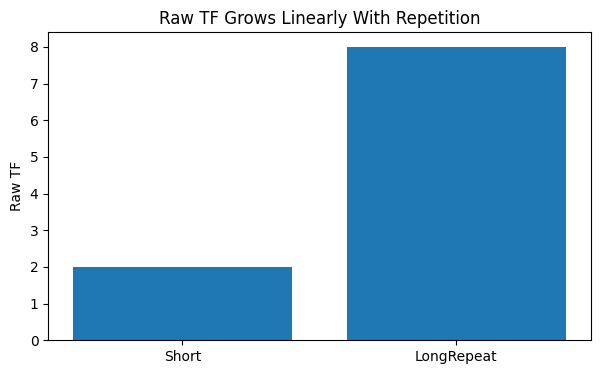

In [10]:
repeat_docs = {
    "Short": "cat cat",
    "LongRepeat": "cat cat cat cat cat cat cat cat"
}

rows = []
for name, text in repeat_docs.items():
    value = tokenize(text).count("cat")
    rows.append({"document": name, "raw_tf": value})

repeat_df = pd.DataFrame(rows)
display(repeat_df)

plt.figure(figsize=(7, 4))
plt.bar(repeat_df["document"], repeat_df["raw_tf"])
plt.ylabel("Raw TF")
plt.title("Raw TF Grows Linearly With Repetition")
plt.show()

# 8. Normalized TF

Long documents naturally contain more words.

One alternative is:

$$
TF_{\text{norm}}(t,d) = \frac{\text{count}(t,d)}{\text{total terms in document}}
$$
Example:

```text
D1: cat cat milk

cat count = 2
total terms = 3

Normalized TF(cat) = 2/3
```

In [11]:
def normalized_tf(term, text):
    tokens = tokenize(text)
    count = tokens.count(term.lower())
    total = len(tokens)
    value = count / total if total else 0

    print("TEXT:", text)
    print("Term count:", count)
    print("Total terms:", total)
    print("Normalized TF:", value)

    return value

normalized_tf("cat", documents["D1"])

TEXT: cat cat milk
Term count: 2
Total terms: 3
Normalized TF: 0.6666666666666666


0.6666666666666666

# 9. Log-Scaled TF

Another idea is to reduce the effect of repeated terms:

$$
TF_{\text{log}} = 1 + \log(tf), \quad tf > 0
$$

Instead of growing linearly, the score grows more slowly.

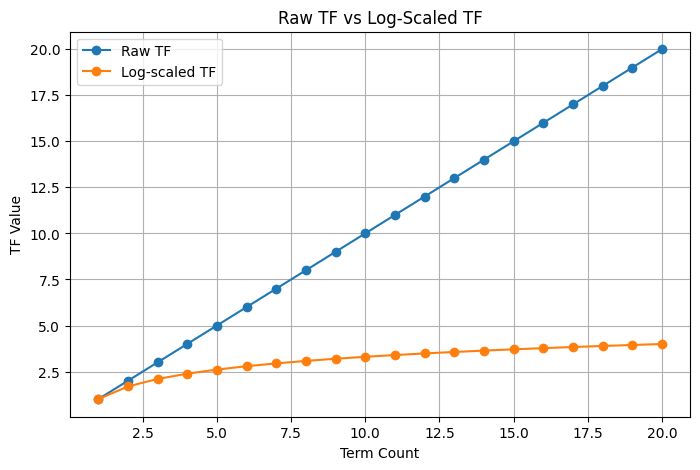

In [12]:
def log_tf(tf_value):
    if tf_value == 0:
        return 0
    return 1 + math.log(tf_value)

x = np.arange(1, 21)
raw = x
log_scaled = [log_tf(v) for v in x]

plt.figure(figsize=(8, 5))
plt.plot(x, raw, marker="o", label="Raw TF")
plt.plot(x, log_scaled, marker="o", label="Log-scaled TF")
plt.xlabel("Term Count")
plt.ylabel("TF Value")
plt.title("Raw TF vs Log-Scaled TF")
plt.legend()
plt.grid(True)
plt.show()

## Interpretation

```text
Raw TF
→ grows linearly

Log-scaled TF
→ grows, but each extra repetition matters less
```

This is a preview of the idea behind BM25 saturation.

# CHECKPOINT 1

### Questions

1. What does TF measure?
2. What is the difference between raw TF and normalized TF?
3. Why can raw TF over-reward repeated words?
4. Why does log-scaled TF grow more slowly?

## CHECKPOINT 1 — Answers

### 1. What does TF measure?

How often a term appears inside a specific document.

### 2. Raw TF vs normalized TF?

```text
Raw TF
= number of occurrences

Normalized TF
= occurrences / total document terms
```

### 3. Why can raw TF over-reward repeated words?

Because every repetition increases the score linearly even when later repetitions add little information.

### 4. Why use log-scaled TF?

To preserve the importance of repetition while reducing its effect as counts become large.

# 10. Document Frequency (DF)

DF asks:

> In how many documents does this term appear?

$$
DF(t) = \text{number of documents containing } t
$$

Example:

```text
D1: cat cat milk
D2: cat dog food
D3: dog dog food

DF(cat)  = 2
DF(dog)  = 2
DF(milk) = 1
```

In [14]:
def document_frequency(term, docs):
    term = term.lower()
    matching = []

    print(f"Calculating DF for: {term}")
    print()
    for doc_id, text in docs.items():
        unique_terms = set(tokenize(text))
        contains = term in unique_terms
        print(f"{doc_id}: contains={contains} | terms={unique_terms}")

        if contains:
            matching.append(doc_id)

    print("\nMatching documents:", matching)
    print("DF:", len(matching))

    return len(matching)

document_frequency("cat", documents)

Calculating DF for: cat

D1: contains=True | terms={'milk', 'cat'}
D2: contains=True | terms={'dog', 'cat', 'food'}
D3: contains=False | terms={'dog', 'food'}
D4: contains=False | terms={'apple', 'fruit', 'banana'}
D5: contains=False | terms={'apple', 'fruit', 'salad'}

Matching documents: ['D1', 'D2']
DF: 2


2

# 11. DF for the Entire Vocabulary

Let's calculate DF for every unique term.

In [15]:
vocabulary = sorted({
    token
    for text in documents.values()
    for token in tokenize(text)
})

print("Vocabulary:")
print(vocabulary)
print("\nVocabulary size:", len(vocabulary))

rows = []
for term in vocabulary:
    df_value = sum(
        1
        for text in documents.values()
        if term in set(tokenize(text))
    )
    rows.append({"term": term, "df": df_value})

df_table = pd.DataFrame(rows).sort_values("df", ascending=False)
display(df_table)

Vocabulary:
['apple', 'banana', 'cat', 'dog', 'food', 'fruit', 'milk', 'salad']

Vocabulary size: 8


,term,df
0,apple,2
2,cat,2
3,dog,2
4,food,2
5,fruit,2
1,banana,1
6,milk,1
7,salad,1


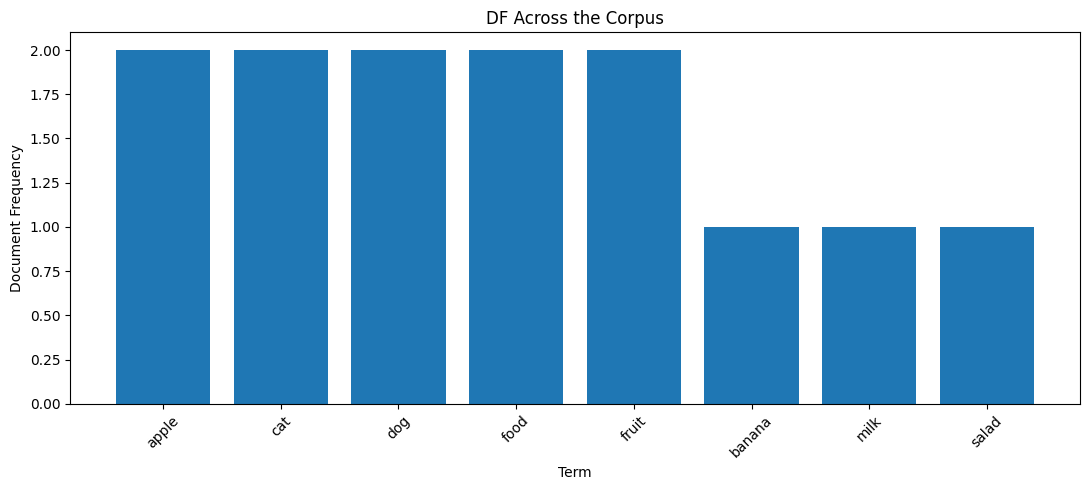

In [16]:
plt.figure(figsize=(11, 5))
plt.bar(df_table["term"], df_table["df"])
plt.xticks(rotation=45)
plt.ylabel("Document Frequency")
plt.xlabel("Term")
plt.title("DF Across the Corpus")
plt.tight_layout()
plt.show()

# 12. Inverse Document Frequency (IDF)

IDF asks:

> How rare is this term across the corpus?

A simplified formula is:

$$
IDF(t) = \log\left(\frac{N}{DF(t)}\right)
$$

where:

- `N` = total number of documents
- `DF(t)` = number of documents containing the term

## Intuition

```text
Large DF
→ term is common
→ lower IDF

Small DF
→ term is rare
→ higher IDF
```

In [17]:
def simple_idf(term, docs):
    N = len(docs)
    df_value = sum(
        1
        for text in docs.values()
        if term.lower() in set(tokenize(text))
    )

    print("Term:", term)
    print("N:", N)
    print("DF:", df_value)

    if df_value == 0:
        print("Term not present in corpus.")
        return None

    ratio = N / df_value
    idf = math.log(ratio)

    print("N / DF:", ratio)
    print("IDF:", idf)

    return idf

simple_idf("milk", documents)

Term: milk
N: 5
DF: 1
N / DF: 5.0
IDF: 1.6094379124341003


1.6094379124341003

# 13. Visual — IDF Falls as DF Increases

For a fixed corpus size:

```text
DF = 1
→ very rare
→ high IDF

DF = N
→ appears everywhere
→ IDF = 0
```

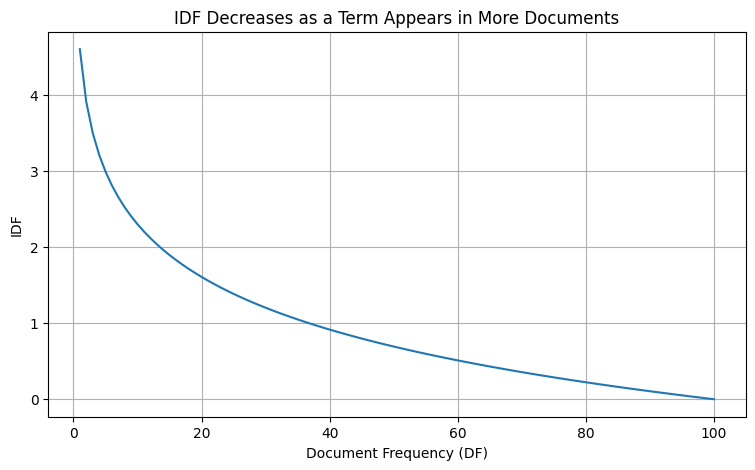

In [18]:
N = 100
possible_df = np.arange(1, N + 1)
idf_values = np.log(N / possible_df)

plt.figure(figsize=(9, 5))
plt.plot(possible_df, idf_values)
plt.xlabel("Document Frequency (DF)")
plt.ylabel("IDF")
plt.title("IDF Decreases as a Term Appears in More Documents")
plt.grid(True)
plt.show()

# 14. Build an IDF Table

Now let's calculate both DF and IDF for every term.

In [19]:
N = len(documents)
idf_rows = []

for term in vocabulary:
    df_value = sum(
        1
        for text in documents.values()
        if term in set(tokenize(text))
    )

    idf_value = math.log(N / df_value)

    idf_rows.append({
        "term": term,
        "df": df_value,
        "idf": idf_value
    })

idf_table = pd.DataFrame(idf_rows).sort_values("idf", ascending=False)
display(idf_table)

,term,df,idf
1,banana,1,1.609438
6,milk,1,1.609438
7,salad,1,1.609438
0,apple,2,0.916291
2,cat,2,0.916291
3,dog,2,0.916291
4,food,2,0.916291
5,fruit,2,0.916291


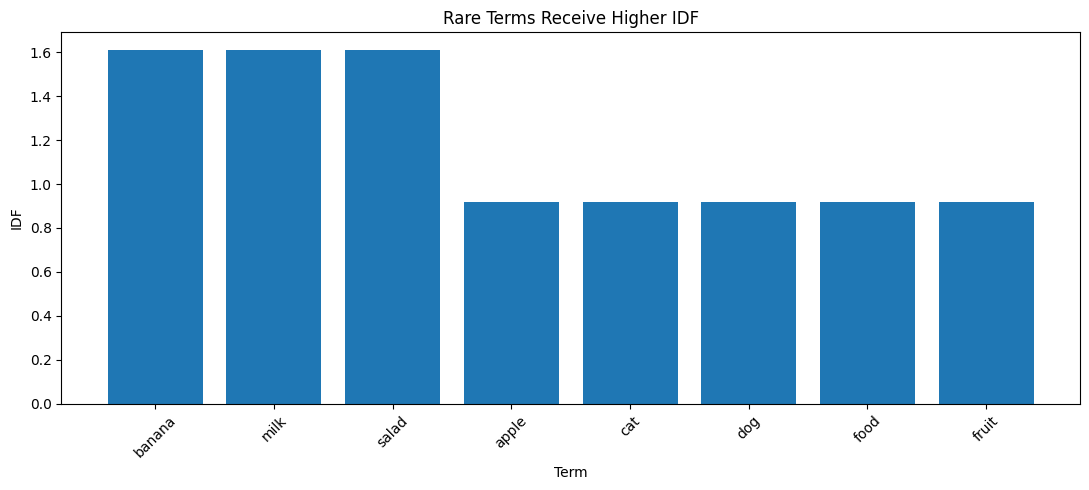

In [20]:
plt.figure(figsize=(11, 5))
plt.bar(idf_table["term"], idf_table["idf"])
plt.xticks(rotation=45)
plt.ylabel("IDF")
plt.xlabel("Term")
plt.title("Rare Terms Receive Higher IDF")
plt.tight_layout()
plt.show()

# 15. Common Word vs Rare Word Example

Imagine 100 documents.

Common word:

```text
DF = 100
IDF = log(100/100) = 0
```

Rare word:

```text
DF = 1
IDF = log(100/1)
```

The rare word is much more informative for search.

In [21]:
N = 100

idf_common = math.log(N / 100)
idf_rare = math.log(N / 1)

print("Common term IDF:", idf_common)
print("Rare term IDF:", idf_rare)

Common term IDF: 0.0
Rare term IDF: 4.605170185988092


# CHECKPOINT 2

### Questions

1. What does DF measure?
2. What does IDF measure?
3. Why do rare words get higher IDF?
4. What happens when DF = N?

## CHECKPOINT 2 — Answers

### 1. What does DF measure?

How many documents contain the term.

### 2. What does IDF measure?

How rare or discriminative a term is across the corpus.

### 3. Why do rare words get higher IDF?

Because they occur in fewer documents and therefore provide stronger evidence for distinguishing relevant documents.

### 4. What happens when DF = N?

$$
IDF = \log\left(\frac{N}{N}\right) = \log(1) = 0
$$
So a term appearing everywhere contributes almost no discriminative value.

# 16. TF-IDF Formula

Now combine local frequency and global rarity:

$$
TFIDF(t,d) = TF(t,d) \times IDF(t)
$$

The ideal high-scoring term is:

```text
frequent in this document
AND
rare across the corpus
```

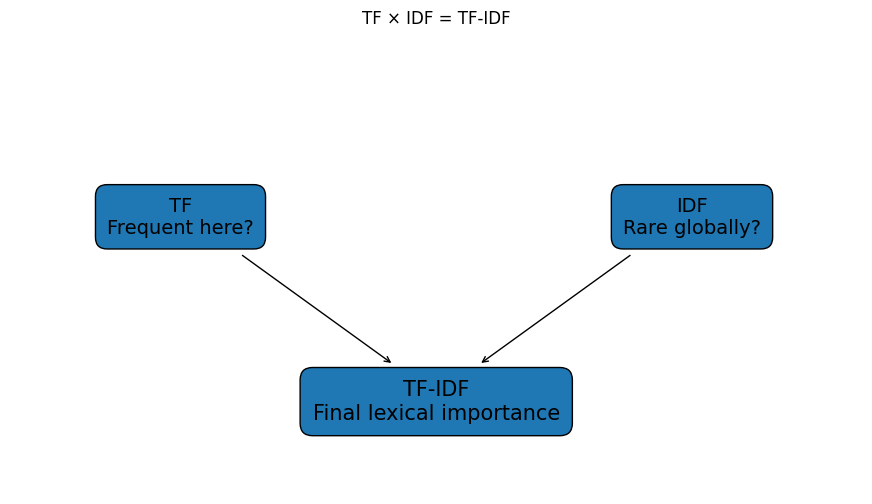

In [22]:
fig, ax = plt.subplots(figsize=(11, 6))
ax.axis("off")

ax.text(0.2, 0.60, "TF\nFrequent here?", ha="center", va="center", fontsize=14,
        bbox=dict(boxstyle="round,pad=0.6"))
ax.text(0.8, 0.60, "IDF\nRare globally?", ha="center", va="center", fontsize=14,
        bbox=dict(boxstyle="round,pad=0.6"))
ax.text(0.5, 0.20, "TF-IDF\nFinal lexical importance", ha="center", va="center", fontsize=15,
        bbox=dict(boxstyle="round,pad=0.6"))

ax.annotate("", xy=(0.45, 0.28), xytext=(0.27, 0.52), arrowprops=dict(arrowstyle="->"))
ax.annotate("", xy=(0.55, 0.28), xytext=(0.73, 0.52), arrowprops=dict(arrowstyle="->"))

plt.title("TF × IDF = TF-IDF")
plt.show()

# 17. Manual TF-IDF Calculation

Let's calculate:

```text
TF-IDF(cat, D1)
```

for:

```text
D1: cat cat milk
```

In [23]:
def tfidf_manual(term, doc_id, docs):
    print("=" * 80)
    print(f"TF-IDF('{term}', {doc_id})")
    print("=" * 80)

    text = docs[doc_id]
    tokens = tokenize(text)

    tf = tokens.count(term.lower())
    print("\nSTEP 1 — TF")
    print("Document:", text)
    print("TF:", tf)

    df_value = sum(
        1
        for other_text in docs.values()
        if term.lower() in set(tokenize(other_text))
    )
    print("\nSTEP 2 — DF")
    print("DF:", df_value)

    N = len(docs)
    idf = math.log(N / df_value) if df_value else 0
    print("\nSTEP 3 — IDF")
    print("N:", N)
    print("IDF:", idf)

    score = tf * idf
    print("\nSTEP 4 — TF × IDF")
    print(f"{tf} × {idf:.4f} = {score:.4f}")

    return score

tfidf_manual("cat", "D1", documents)

TF-IDF('cat', D1)

STEP 1 — TF
Document: cat cat milk
TF: 2

STEP 2 — DF
DF: 2

STEP 3 — IDF
N: 5
IDF: 0.9162907318741551

STEP 4 — TF × IDF
2 × 0.9163 = 1.8326


1.8325814637483102

# 18. Compare Two Terms in the Same Document

In:

```text
D1: cat cat milk
```

- `cat` has higher TF
- `milk` may have higher IDF

So final TF-IDF depends on both.

TF-IDF('cat', D1)

STEP 1 — TF
Document: cat cat milk
TF: 2

STEP 2 — DF
DF: 2

STEP 3 — IDF
N: 5
IDF: 0.9162907318741551

STEP 4 — TF × IDF
2 × 0.9163 = 1.8326
TF-IDF('milk', D1)

STEP 1 — TF
Document: cat cat milk
TF: 1

STEP 2 — DF
DF: 1

STEP 3 — IDF
N: 5
IDF: 1.6094379124341003

STEP 4 — TF × IDF
1 × 1.6094 = 1.6094


,term,tfidf
0,cat,1.832581
1,milk,1.609438


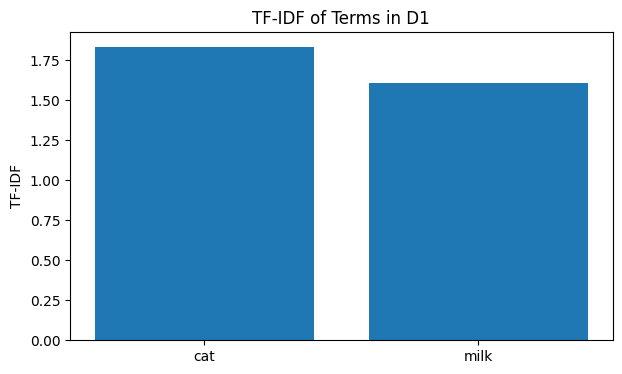

In [24]:
comparison = []

for term in ["cat", "milk"]:
    score = tfidf_manual(term, "D1", documents)
    comparison.append({"term": term, "tfidf": score})

comparison_df = pd.DataFrame(comparison)
display(comparison_df)

plt.figure(figsize=(7, 4))
plt.bar(comparison_df["term"], comparison_df["tfidf"])
plt.ylabel("TF-IDF")
plt.title("TF-IDF of Terms in D1")
plt.show()

# 19. Build a Complete TF-IDF Matrix From Scratch

Conceptually:

```text
         cat  dog  milk  food  apple  fruit ...
D1
D2
D3
D4
D5
```

Rows:

```text
documents
```

Columns:

```text
vocabulary terms
```

Cells:

```text
TF-IDF weights
```

In [25]:
def build_tfidf_matrix(docs):
    vocab = sorted({
        token
        for text in docs.values()
        for token in tokenize(text)
    })

    doc_ids = list(docs.keys())
    N = len(docs)

    df_map = {}
    for term in vocab:
        df_map[term] = sum(
            1
            for text in docs.values()
            if term in set(tokenize(text))
        )

    idf_map = {
        term: math.log(N / df_map[term])
        for term in vocab
    }

    matrix = []

    for doc_id in doc_ids:
        counts = Counter(tokenize(docs[doc_id]))
        row = []

        print(f"\nBuilding row for {doc_id}")

        for term in vocab:
            tf = counts[term]
            idf = idf_map[term]
            score = tf * idf
            row.append(score)

            if tf > 0:
                print(
                    f"{term:<10} TF={tf:<2} IDF={idf:.4f} TF-IDF={score:.4f}"
                )

        matrix.append(row)

    frame = pd.DataFrame(matrix, index=doc_ids, columns=vocab)
    return frame, idf_map

manual_matrix, manual_idf = build_tfidf_matrix(documents)

display(manual_matrix.round(3))


Building row for D1
cat        TF=2  IDF=0.9163 TF-IDF=1.8326
milk       TF=1  IDF=1.6094 TF-IDF=1.6094

Building row for D2
cat        TF=1  IDF=0.9163 TF-IDF=0.9163
dog        TF=1  IDF=0.9163 TF-IDF=0.9163
food       TF=1  IDF=0.9163 TF-IDF=0.9163

Building row for D3
dog        TF=2  IDF=0.9163 TF-IDF=1.8326
food       TF=1  IDF=0.9163 TF-IDF=0.9163

Building row for D4
apple      TF=1  IDF=0.9163 TF-IDF=0.9163
banana     TF=1  IDF=1.6094 TF-IDF=1.6094
fruit      TF=1  IDF=0.9163 TF-IDF=0.9163

Building row for D5
apple      TF=1  IDF=0.9163 TF-IDF=0.9163
fruit      TF=1  IDF=0.9163 TF-IDF=0.9163
salad      TF=1  IDF=1.6094 TF-IDF=1.6094


,apple,banana,cat,dog,food,fruit,milk,salad
D1,0.000,0.000,1.833,0.000,0.000,0.000,1.609,0.000
D2,0.000,0.000,0.916,0.916,0.916,0.000,0.000,0.000
D3,0.000,0.000,0.000,1.833,0.916,0.000,0.000,0.000
D4,0.916,1.609,0.000,0.000,0.000,0.916,0.000,0.000
D5,0.916,0.000,0.000,0.000,0.000,0.916,0.000,1.609


# 20. Visualize the TF-IDF Matrix

A heatmap makes the sparse structure easier to see.

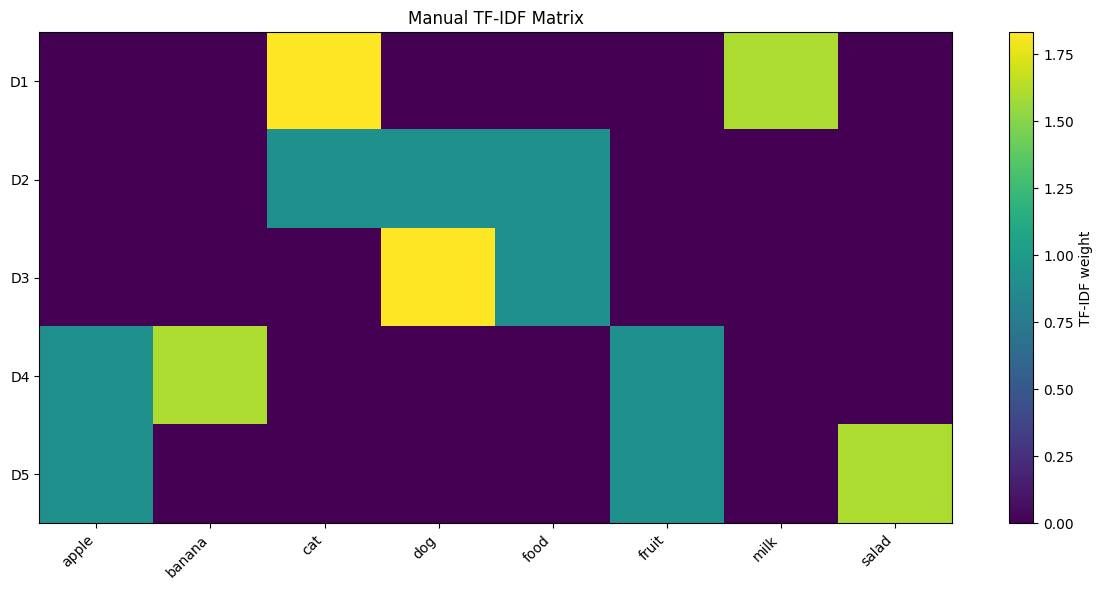

In [26]:
plt.figure(figsize=(12, 6))
plt.imshow(manual_matrix.values, aspect="auto")
plt.colorbar(label="TF-IDF weight")
plt.xticks(range(len(manual_matrix.columns)), manual_matrix.columns, rotation=45, ha="right")
plt.yticks(range(len(manual_matrix.index)), manual_matrix.index)
plt.title("Manual TF-IDF Matrix")
plt.tight_layout()
plt.show()

# 21. Why TF-IDF Is Sparse

Imagine a vocabulary of 100,000 terms.

A short document may contain only 20.

Conceptually:

```text
[0, 0, 0, 0.72, 0, 0, 1.31, 0, 0, ...]
```

Most dimensions are zero.

Hence:

```text
TF-IDF = sparse vector representation
```

In [27]:
d1 = manual_matrix.loc["D1"]

print("Full vector dimensions:", len(d1))
print("\nNon-zero features:")
display(d1[d1 > 0])

Full vector dimensions: 8

Non-zero features:


cat     1.832581
milk    1.609438
Name: D1, dtype: float64

# CHECKPOINT 3

### Questions

1. What does TF-IDF combine?
2. When does a term get high TF-IDF?
3. Why is the TF-IDF matrix sparse?
4. What do rows and columns represent?

## CHECKPOINT 3 — Answers

### 1. What does TF-IDF combine?

```text
TF  → local frequency
IDF → global rarity
```

### 2. When is TF-IDF high?

When a term:

```text
appears frequently in this document
AND
appears in relatively few other documents
```

### 3. Why sparse?

Each document contains only a small fraction of the entire vocabulary.

### 4. Rows and columns?

```text
Rows    = documents
Columns = terms
Cells   = TF-IDF weights
```

# 22. Query TF-IDF Vector

Suppose the user searches:

```text
cat milk
```

The query must use the **same vocabulary dimensions** as the documents.

Pipeline:

```text
Query
 ↓
Tokenize
 ↓
Count terms
 ↓
Apply corpus IDF values
 ↓
Query TF-IDF vector
```

In [28]:
def build_query_vector(query, vocabulary, idf_map):
    tokens = tokenize(query)
    counts = Counter(tokens)

    print("QUERY:", query)
    print("TOKENS:", tokens)

    values = []

    print("\nACTIVE QUERY FEATURES")

    for term in vocabulary:
        tf = counts[term]
        idf = idf_map.get(term, 0)
        score = tf * idf
        values.append(score)

        if tf > 0:
            print(
                f"{term:<10} TF={tf} IDF={idf:.4f} TF-IDF={score:.4f}"
            )

    return np.array(values, dtype=float)

query_vector = build_query_vector(
    "cat milk",
    list(manual_matrix.columns),
    manual_idf
)

print("\nQuery vector shape:", query_vector.shape)
print("Query vector:", query_vector)

QUERY: cat milk
TOKENS: ['cat', 'milk']

ACTIVE QUERY FEATURES
cat        TF=1 IDF=0.9163 TF-IDF=0.9163
milk       TF=1 IDF=1.6094 TF-IDF=1.6094

Query vector shape: (8,)
Query vector: [0.         0.         0.91629073 0.         0.         0.
 1.60943791 0.        ]


# 23. Cosine Similarity for Ranking

Now we compare:

```text
query TF-IDF vector
vs
document TF-IDF vectors
```

using:

$$
\cos(\theta) = \frac{Q \cdot D}{\|Q\| \, \|D\|}
$$

Higher cosine similarity means stronger lexical alignment.

In [29]:
def cosine_manual(a, b):
    dot = np.dot(a, b)
    norm_a = np.linalg.norm(a)
    norm_b = np.linalg.norm(b)

    if norm_a == 0 or norm_b == 0:
        return 0.0

    return dot / (norm_a * norm_b)

rows = []
for doc_id in manual_matrix.index:
    doc_vector = manual_matrix.loc[doc_id].values
    score = cosine_manual(query_vector, doc_vector)
    print(f"{doc_id}: {score:.4f}")
    rows.append({"doc_id": doc_id, "score": score})

score_df = pd.DataFrame(rows).sort_values("score", ascending=False)
display(score_df)

D1: 0.9452
D2: 0.2856
D3: 0.0000
D4: 0.0000
D5: 0.0000


,doc_id,score
0,D1,0.945203
1,D2,0.285649
2,D3,0.000000
3,D4,0.000000
4,D5,0.000000


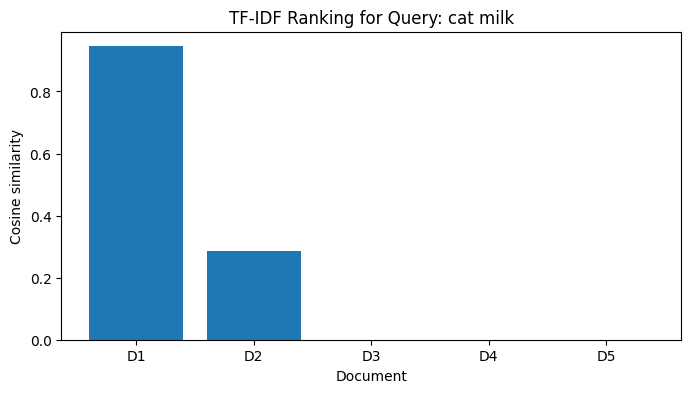

In [30]:
plt.figure(figsize=(8, 4))
plt.bar(score_df["doc_id"], score_df["score"])
plt.ylabel("Cosine similarity")
plt.xlabel("Document")
plt.title("TF-IDF Ranking for Query: cat milk")
plt.show()

# 24. End-to-End TF-IDF Search From Scratch

```text
Query
 ↓
Tokenize
 ↓
Query TF-IDF vector
 ↓
Compare with document vectors
 ↓
Cosine similarity
 ↓
Sort
 ↓
Top-K
```

In [31]:
def tfidf_search_from_scratch(query, matrix, idf_map, top_k=3):
    print("=" * 90)
    print("TF-IDF SEARCH FROM SCRATCH")
    print("=" * 90)

    vocabulary = list(matrix.columns)

    print("\nSTEP 1 — QUERY")
    print(query)

    print("\nSTEP 2 — QUERY VECTOR")
    q = build_query_vector(query, vocabulary, idf_map)

    print("\nSTEP 3 — DOCUMENT SIMILARITIES")
    rows = []

    for doc_id in matrix.index:
        d = matrix.loc[doc_id].values
        score = cosine_manual(q, d)
        print(f"{doc_id}: {score:.4f}")
        rows.append({"doc_id": doc_id, "score": score})

    ranked = pd.DataFrame(rows).sort_values("score", ascending=False).head(top_k)

    print(f"\nSTEP 4 — TOP-{top_k}")
    display(ranked)

    return ranked

tfidf_search_from_scratch("apple fruit", manual_matrix, manual_idf, top_k=3)

TF-IDF SEARCH FROM SCRATCH

STEP 1 — QUERY
apple fruit

STEP 2 — QUERY VECTOR
QUERY: apple fruit
TOKENS: ['apple', 'fruit']

ACTIVE QUERY FEATURES
apple      TF=1 IDF=0.9163 TF-IDF=0.9163
fruit      TF=1 IDF=0.9163 TF-IDF=0.9163

STEP 3 — DOCUMENT SIMILARITIES
D1: 0.0000
D2: 0.0000
D3: 0.0000
D4: 0.6271
D5: 0.6271

STEP 4 — TOP-3


,doc_id,score
3,D4,0.627136
4,D5,0.627136
0,D1,0.000000


,doc_id,score
3,D4,0.627136
4,D5,0.627136
0,D1,0.000000


# 25. Scikit-Learn TF-IDF

Now that we understand the internals, we can use:

```python
TfidfVectorizer
```

It handles:

```text
tokenization
vocabulary
TF
IDF
TF-IDF matrix
normalization
```

In [32]:
vectorizer = TfidfVectorizer()

doc_ids = list(documents.keys())
doc_texts = list(documents.values())

sk_matrix = vectorizer.fit_transform(doc_texts)

print("Matrix shape:", sk_matrix.shape)
print("Vocabulary size:", len(vectorizer.get_feature_names_out()))

Matrix shape: (5, 8)
Vocabulary size: 8


In [33]:
features = vectorizer.get_feature_names_out()

sk_df = pd.DataFrame(
    sk_matrix.toarray(),
    index=doc_ids,
    columns=features
)

display(sk_df.round(3))

,apple,banana,cat,dog,food,fruit,milk,salad
D1,0.000,0.000,0.850,0.000,0.000,0.000,0.527,0.000
D2,0.000,0.000,0.577,0.577,0.577,0.000,0.000,0.000
D3,0.000,0.000,0.000,0.894,0.447,0.000,0.000,0.000
D4,0.532,0.659,0.000,0.000,0.000,0.532,0.000,0.000
D5,0.532,0.000,0.000,0.000,0.000,0.532,0.000,0.659


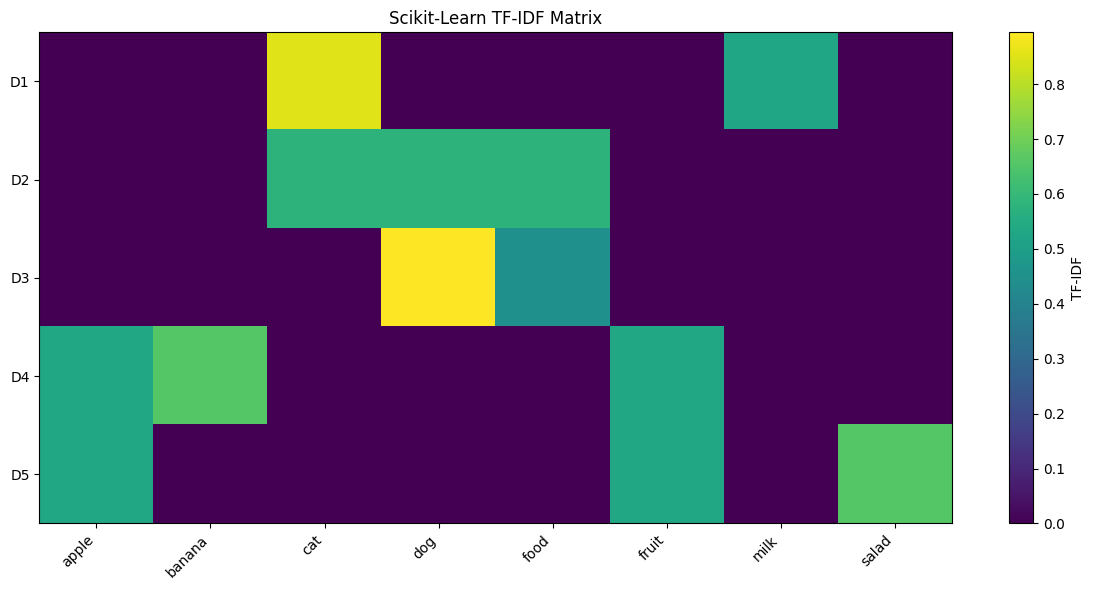

In [34]:
plt.figure(figsize=(12, 6))
plt.imshow(sk_df.values, aspect="auto")
plt.colorbar(label="TF-IDF")
plt.xticks(range(len(features)), features, rotation=45, ha="right")
plt.yticks(range(len(doc_ids)), doc_ids)
plt.title("Scikit-Learn TF-IDF Matrix")
plt.tight_layout()
plt.show()

# 26. Important: `fit_transform()` vs `transform()`

For documents:

```python
fit_transform()
```

because we need to learn:

```text
vocabulary
IDF statistics
```

For a new query:

```python
transform()
```

because the query must reuse the existing corpus vocabulary and IDF values.

In [35]:
def sklearn_tfidf_search(query, vectorizer, document_matrix, doc_ids, top_k=3):
    print("=" * 80)
    print("SCIKIT-LEARN TF-IDF SEARCH")
    print("=" * 80)

    print("\nQUERY:", query)

    q = vectorizer.transform([query])
    print("Query vector shape:", q.shape)

    names = vectorizer.get_feature_names_out()
    active = q.nonzero()[1]

    print("\nNON-ZERO QUERY FEATURES")
    if len(active) == 0:
        print("None")
    else:
        for idx in active:
            print(f"{names[idx]:<12} {q[0, idx]:.4f}")

    similarities = cosine_similarity(q, document_matrix).flatten()

    print("\nSIMILARITIES")
    for doc_id, score in zip(doc_ids, similarities):
        print(f"{doc_id}: {score:.4f}")

    ranking = np.argsort(similarities)[::-1][:top_k]

    result = pd.DataFrame({
        "doc_id": [doc_ids[i] for i in ranking],
        "score": [similarities[i] for i in ranking]
    })

    print(f"\nTOP-{top_k}")
    display(result)
    return result

sklearn_tfidf_search("apple fruit", vectorizer, sk_matrix, doc_ids, top_k=3)

SCIKIT-LEARN TF-IDF SEARCH

QUERY: apple fruit
Query vector shape: (1, 8)

NON-ZERO QUERY FEATURES
apple        0.7071
fruit        0.7071

SIMILARITIES
D1: 0.0000
D2: 0.0000
D3: 0.0000
D4: 0.7520
D5: 0.7520

TOP-3


,doc_id,score
0,D5,0.75204
1,D4,0.75204
2,D3,0.00000


,doc_id,score
0,D5,0.75204
1,D4,0.75204
2,D3,0.00000


# 27. Out-of-Vocabulary (OOV) Query Terms

Suppose the query contains:

```text
orange
```

but `orange` never appeared in the indexed corpus.

Then the vocabulary has no feature for it.

```text
unknown term
→ no dimension
→ no lexical signal
```

In [36]:
q = vectorizer.transform(["orange"])

print("Non-zero query values:", q.nnz)
print("Query vector:")
print(q.toarray())

Non-zero query values: 0
Query vector:
[[0. 0. 0. 0. 0. 0. 0. 0.]]


This is one reason dense semantic retrieval is useful in Hybrid Search.

# 28. Synonym Failure

TF-IDF is lexical.

So:

```text
car
```

and:

```text
automobile
```

are different terms.

TF-IDF does not automatically know they are synonyms.

In [37]:
syn_docs = [
    "automobile repair guide",
    "car insurance policy",
    "bicycle repair manual"
]

syn_vec = TfidfVectorizer()
syn_matrix = syn_vec.fit_transform(syn_docs)
syn_query = syn_vec.transform(["car repair"])
syn_scores = cosine_similarity(syn_query, syn_matrix).flatten()

for i, score in enumerate(syn_scores):
    print(f"D{i+1}: {syn_docs[i]} -> {score:.4f}")

D1: automobile repair guide -> 0.2867
D2: car insurance policy -> 0.4595
D3: bicycle repair manual -> 0.2867


# 29. Long-Document Limitation

Consider:

```text
D1: cat milk

D2: cat milk + hundreds of unrelated words
```

TF-IDF can normalize vectors, but classical TF-IDF does not model document length in the same explicit way BM25 does.

BM25 later introduces:

```text
document length normalization
average document length
parameter b
```

# 30. Repeated-Term Limitation

Raw TF-based TF-IDF keeps increasing as a term repeats.

```text
1 apple
2 apples
10 apples
100 apples
```

Each increase can continue raising raw TF contribution.

BM25 instead uses **term-frequency saturation**.

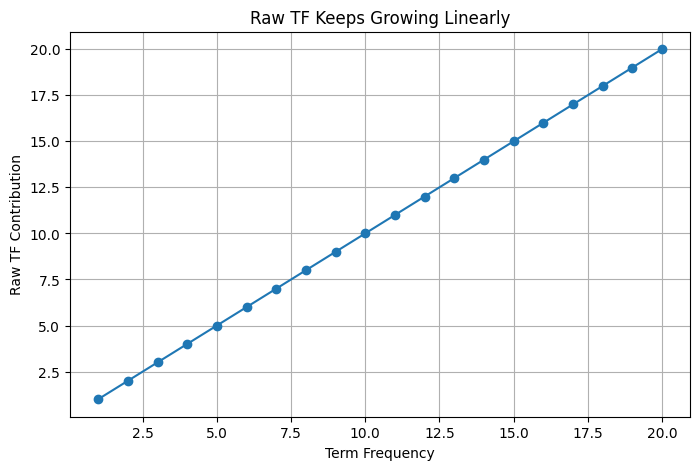

In [38]:
tf_counts = np.arange(1, 21)

plt.figure(figsize=(8, 5))
plt.plot(tf_counts, tf_counts, marker="o")
plt.xlabel("Term Frequency")
plt.ylabel("Raw TF Contribution")
plt.title("Raw TF Keeps Growing Linearly")
plt.grid(True)
plt.show()

# 31. Binary Match vs TF-IDF

Boolean search asks:

```text
Does the term exist?
```

TF-IDF asks:

```text
How strongly does this document represent the term?
```

Example:

```text
D1: cat
D2: cat cat cat
```

Boolean:

```text
both match
```

TF-based weighting:

```text
D2 can receive stronger term weight
```

In [39]:
binary_example = pd.DataFrame({
    "document": ["D1", "D2"],
    "contains_cat": [1, 1],
    "raw_tf_cat": [1, 3]
})

display(binary_example)

,document,contains_cat,raw_tf_cat
0,D1,1,1
1,D2,1,3


# 32. TF-IDF End-to-End Visual

```text
                 DOCUMENTS
                     │
                     ▼
                TOKENIZATION
                     │
                     ▼
                 VOCABULARY
                     │
          ┌──────────┴──────────┐
          ▼                     ▼
         TF                    DF
          │                     │
          │                     ▼
          │                    IDF
          │                     │
          └──────────┬──────────┘
                     ▼
                   TF-IDF
                     │
                     ▼
              DOCUMENT VECTORS
                     │
                     ▼
                  QUERY
                     │
                     ▼
             QUERY TF-IDF VECTOR
                     │
                     ▼
             COSINE SIMILARITY
                     │
                     ▼
                   TOP-K
```

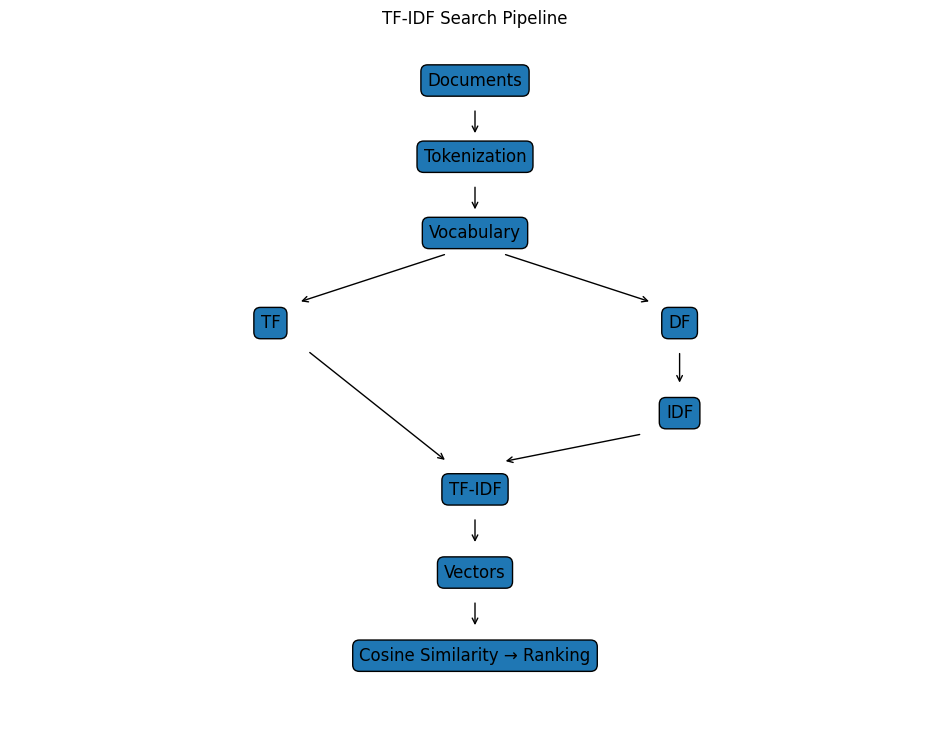

In [41]:
fig, ax = plt.subplots(figsize=(12, 9))
ax.axis("off")

nodes = [
    (0.5, 0.93, "Documents"),
    (0.5, 0.82, "Tokenization"),
    (0.5, 0.71, "Vocabulary"),
    (0.28, 0.58, "TF"),
    (0.72, 0.58, "DF"),
    (0.72, 0.45, "IDF"),
    (0.5, 0.34, "TF-IDF"),
    (0.5, 0.22, "Vectors"),
    (0.5, 0.10, "Cosine Similarity → Ranking")
]

for x, y, label in nodes:
    ax.text(x, y, label, ha="center", va="center", fontsize=12,
            bbox=dict(boxstyle="round,pad=0.4"))

connections = [
    ((0.5, 0.89), (0.5, 0.85)),
    ((0.5, 0.78), (0.5, 0.74)),
    ((0.47, 0.68), (0.31, 0.61)),
    ((0.53, 0.68), (0.69, 0.61)),
    ((0.72, 0.54), (0.72, 0.49)),
    ((0.32, 0.54), (0.47, 0.38)),
    ((0.68, 0.42), (0.53, 0.38)),
    ((0.5, 0.30), (0.5, 0.26)),
    ((0.5, 0.18), (0.5, 0.14))
]

for start, end in connections:
    ax.annotate("", xy=end, xytext=start, arrowprops=dict(arrowstyle="->"))

plt.title("TF-IDF Search Pipeline")
plt.show()

# CHECKPOINT 4

### Questions

1. Why must query and document vectors use the same vocabulary?
2. Why does TF-IDF fail on unseen query terms?
3. Why do synonyms cause trouble?
4. What is cosine similarity doing?
5. Why is repeated-term growth a limitation?

## CHECKPOINT 4 — Answers

### 1. Why the same vocabulary?

Because every vector dimension must represent the same term in query and documents.

### 2. Why do unseen terms fail?

There is no learned vocabulary dimension for them, so they contribute no lexical signal.

### 3. Why do synonyms cause trouble?

TF-IDF matches words rather than meaning.

```text
car ≠ automobile
```

### 4. What does cosine similarity do?

It measures how strongly the query and document TF-IDF vectors align.

### 5. Why is repeated-term growth a limitation?

Raw TF can keep increasing with every repetition even when later repetitions add little extra relevance.

# 33. Why BM25 Improves on TF-IDF

BM25 adds two major improvements.

## Improvement 1 — TF Saturation

Instead of:

```text
10 occurrences = 10× as valuable as 1
```

BM25 makes later repetitions matter less.

## Improvement 2 — Document-Length Normalization

BM25 explicitly adjusts for long vs short documents.

Learning progression:

```text
Boolean Search
    ↓
TF
    ↓
TF-IDF
    ↓
BM25
```

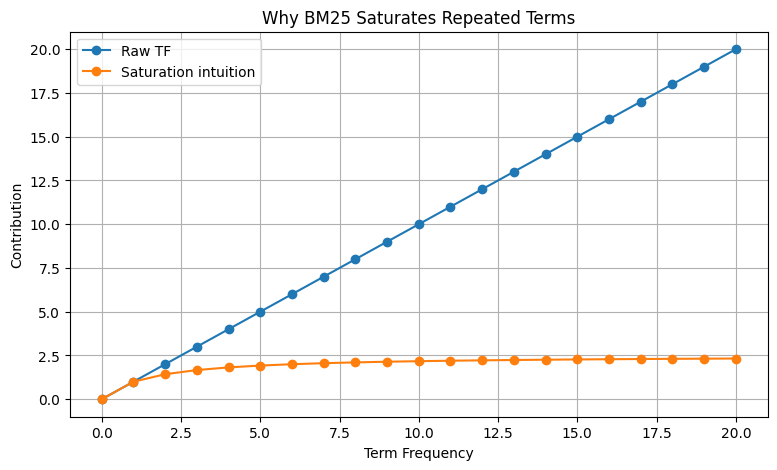

In [43]:
tf_values = np.arange(0, 21)
raw = tf_values
k = 1.5
saturated = tf_values * (k + 1) / (tf_values + k + 1e-12)

plt.figure(figsize=(9, 5))
plt.plot(tf_values, raw, marker="o", label="Raw TF")
plt.plot(tf_values, saturated, marker="o", label="Saturation intuition")
plt.xlabel("Term Frequency")
plt.ylabel("Contribution")
plt.title("Why BM25 Saturates Repeated Terms")
plt.legend()
plt.grid(True)
plt.show()

# 34. TF-IDF Strengths and Weaknesses

| Capability | TF-IDF |
|---|---|
| Exact keywords | Strong |
| Rare terms | Strong |
| Explainability | Strong |
| Sparse storage | Strong |
| Synonyms | Weak |
| Semantic meaning | Weak |
| Unseen vocabulary | Weak |
| Repetition handling | Limited |
| Explicit length normalization | Limited |
| Exact IDs/codes | Strong |

This is why TF-IDF is foundational but not the final lexical ranking method.

# 35. TF-IDF Debugging Framework

If search looks wrong, inspect:

```text
1. Was tokenization correct?
2. Is the query term in vocabulary?
3. What is TF?
4. What is DF?
5. What is IDF?
6. Is TF-IDF too small?
7. Is query vector mostly zero?
8. Is cosine similarity low?
9. Is vocabulary mismatch happening?
10. Is the document long/noisy?
```

In [45]:
def debug_tfidf_query(query, vectorizer, doc_matrix, doc_ids):
    print("=" * 90)
    print("TF-IDF DEBUG")
    print("=" * 90)

    print("\nQUERY:", query)

    q = vectorizer.transform([query])
    features = vectorizer.get_feature_names_out()
    active = q.nonzero()[1]

    print("\nNON-ZERO QUERY FEATURES")
    if len(active) == 0:
        print("NONE — possible out-of-vocabulary query.")
    else:
        for idx in active:
            print(features[idx])

    scores = cosine_similarity(q, doc_matrix).flatten()

    print("\nDOCUMENT SCORES")
    for doc_id, score in zip(doc_ids, scores):
        print(f"{doc_id}: {score:.4f}")

debug_tfidf_query("orange", vectorizer, sk_matrix, doc_ids)

TF-IDF DEBUG

QUERY: orange

NON-ZERO QUERY FEATURES
NONE — possible out-of-vocabulary query.

DOCUMENT SCORES
D1: 0.0000
D2: 0.0000
D3: 0.0000
D4: 0.0000
D5: 0.0000


# 36. Interview Questions

### What is TF-IDF?

A lexical weighting method combining term frequency in one document with inverse document frequency across the corpus.

### Why use IDF?

Common words are weak discriminators; rare words are more informative.

### What if a term appears in every document?

Its simplified IDF becomes zero.

### Why is TF-IDF sparse?

Each document contains only a small subset of the vocabulary.

### How does TF-IDF search work?

```text
documents → TF-IDF vectors
query → TF-IDF vector
cosine similarity → ranking
```

### Why does TF-IDF fail on synonyms?

Because it matches lexical features, not semantic meaning.

### Why does BM25 improve on TF-IDF?

It adds TF saturation and document-length normalization.

# 37. Interview Scenarios

### Scenario 1

```text
D1: apple apple banana
D2: apple orange
```

Query:

```text
apple
```

Which document has higher raw TF for `apple`?

**D1**.

---

### Scenario 2

A term appears in only 1 of 10,000 documents.

Is IDF high or low?

**High**, because the term is rare.

---

### Scenario 3

Query:

```text
car repair
```

Document:

```text
automobile maintenance
```

Why can TF-IDF fail?

Because vocabulary differs despite related meaning.

---

### Scenario 4

Why use `transform()` for a query instead of `fit_transform()`?

Because the query must reuse the corpus vocabulary and IDF statistics.

---

### Scenario 5

Why can a term repeated 100 times be overvalued by raw TF?

Because raw TF grows approximately linearly. BM25 reduces this using saturation.

# 38. One-Page Revision Map

```text
                    TF-IDF
                      │
           ┌──────────┴──────────┐
           │                     │
           ▼                     ▼
          TF                    IDF
           │                     │
   frequency in doc       rarity in corpus
           │                     │
           ▼                     ▼
     count / normalized      log(N / DF)
           │                     │
           └──────────┬──────────┘
                      ▼
                   TF × IDF
                      │
                      ▼
                 Sparse Vector
                      │
                      ▼
              Query TF-IDF Vector
                      │
                      ▼
              Cosine Similarity
                      │
                      ▼
                   Ranking
```

Key formulas:

$$
TF(t,d) = \text{count}(t,d)
$$

$$
DF(t) = \text{number of documents containing } t
$$

$$
IDF(t) = \log\left(\frac{N}{DF(t)}\right)
$$

$$
TFIDF(t,d) = TF(t,d) \times IDF(t)
$$

# 39. Practice Tasks

### Task 1

Use:

```text
D1: apple apple banana
D2: apple orange banana
D3: grape orange
```

Calculate manually:

```text
TF(apple, D1)
DF(apple)
IDF(apple)
TF-IDF(apple, D1)
```

### Task 2

Compare IDF of:

```text
banana
grape
```

Which is larger and why?

### Task 3

Build the full TF-IDF matrix manually.

### Task 4

Search:

```text
apple banana
```

using cosine similarity.

### Task 5

Add the word `fruit` to every document and inspect how IDF changes.

### Task 6

Compare:

```text
D1: cat
D2: cat cat cat cat cat
```

### Task 7

Test vocabulary mismatch:

```text
query: car
document: automobile
```

### Task 8

Compare your manual matrix with `TfidfVectorizer`.

# 40. Final Takeaways

Remember these ten ideas:

1. TF measures local term frequency.
2. DF counts documents containing a term.
3. IDF measures global rarity.
4. Rare terms receive higher IDF.
5. TF-IDF combines local importance and global rarity.
6. TF-IDF documents are sparse vectors.
7. Queries must use the same vocabulary as documents.
8. Cosine similarity can rank query-document TF-IDF vectors.
9. TF-IDF is lexical and therefore weak on synonyms/semantics.
10. BM25 improves TF-IDF with TF saturation and document-length normalization.

---

# Next Chapter — Chapter 5: BM25

Chapter 5 will be a **deep-dive notebook** because BM25 is one of the most important Hybrid Search topics.

We will cover:

```text
Why TF-IDF is insufficient
BM25 formula
BM25 IDF
TF saturation
k1
b
document length normalization
average document length
manual calculations
visual parameter experiments
BM25 from scratch
rank_bm25
BM25 vs TF-IDF
failure cases
interview questions
```